* PdM_errors.csv:is an error log of 3 features dataset : datatime as an hourly
- Index
- MachineId
- Error

Indicates the type of error encountered by the machine during operation.



* PdM_telemetry.csv: It consists of hourly average of voltage, rotation, pressure, vibration collected from 100 machines for the year 2015

* PdM maint.csv: This dataset contains a record for each time a machine component is changed.

* PdM_failures.csv dataset: this dataset contains an 

# 1. LOAD DATA

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

#Load the data
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
# pd.set_option("display.width", 80)
# pd.set_option("display.max_colwidth", 15)

telemetry_df = pd.read_csv("Datasets/PdM_telemetry.csv")
errors_df = pd.read_csv("Datasets/PdM_errors.csv")
maint_df = pd.read_csv("Datasets/PdM_maint.csv")
failures_df = pd.read_csv("Datasets/PdM_failures.csv")
machines_df = pd.read_csv("Datasets/PdM_machines.csv")


- telemetry: 876,100 filas (100 máquinas × 8,761 horas de 2015)
- Label Y - failures: 761 fallas (comp2: 259, comp1: 192, comp4: 179, comp3: 131).
- errors: 3,919 errores (Non stop machine warnings)
    Note: an error does not cause the machine to stop so it is not considered as failure
- maint: 3,286 Component Replacements, included 2014 
- machines: Model (model1–4) Machine age. Hourly record of the failed component in a machine of 100 machines

### ------------------------------ TELEMETRY

In [2]:
print(telemetry_df.describe().round(2).transpose())

              count    mean    std     min     25%     50%     75%     max
machineID  876100.0   50.50  28.87    1.00   25.75   50.50   75.25  100.00
volt       876100.0  170.78  15.51   97.33  160.30  170.61  181.00  255.12
rotate     876100.0  446.61  52.67  138.43  412.31  447.56  482.18  695.02
pressure   876100.0  100.86  11.05   51.24   93.50  100.43  107.56  185.95
vibration  876100.0   40.39   5.37   14.88   36.78   40.24   43.78   76.79


In [3]:
print(telemetry_df[telemetry_df.machineID == 100].head())

                   datetime  machineID        volt      rotate    pressure  vibration
867339  2015-01-01 06:00:00        100  161.587466  399.879713  105.314528  38.559006
867340  2015-01-01 07:00:00        100  163.333175  394.459364  105.535345  36.987566
867341  2015-01-01 08:00:00        100  153.926056  436.009858   78.786105  42.694210
867342  2015-01-01 09:00:00        100  174.653605  538.500425  109.914808  45.124346
867343  2015-01-01 10:00:00        100  199.637542  460.306816   86.520963  44.259918


In [4]:
print("Number of machines:",telemetry_df.machineID.nunique())

Number of machines: 100


In [5]:
telemetry_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 876100 entries, 0 to 876099
Data columns (total 6 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   datetime   876100 non-null  str    
 1   machineID  876100 non-null  int64  
 2   volt       876100 non-null  float64
 3   rotate     876100 non-null  float64
 4   pressure   876100 non-null  float64
 5   vibration  876100 non-null  float64
dtypes: float64(4), int64(1), str(1)
memory usage: 40.1 MB


In [6]:
telemetry_df["datetime"] = pd.to_datetime(telemetry_df["datetime"])
telemetry_df['datetime'].dtype

dtype('<M8[us]')

### Box plot VOLTAGE BY MACHINE

C:\Users\User\AppData\Local\Temp\ipykernel_46188\1462299642.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(values, vert=False, tick_labels=labels)


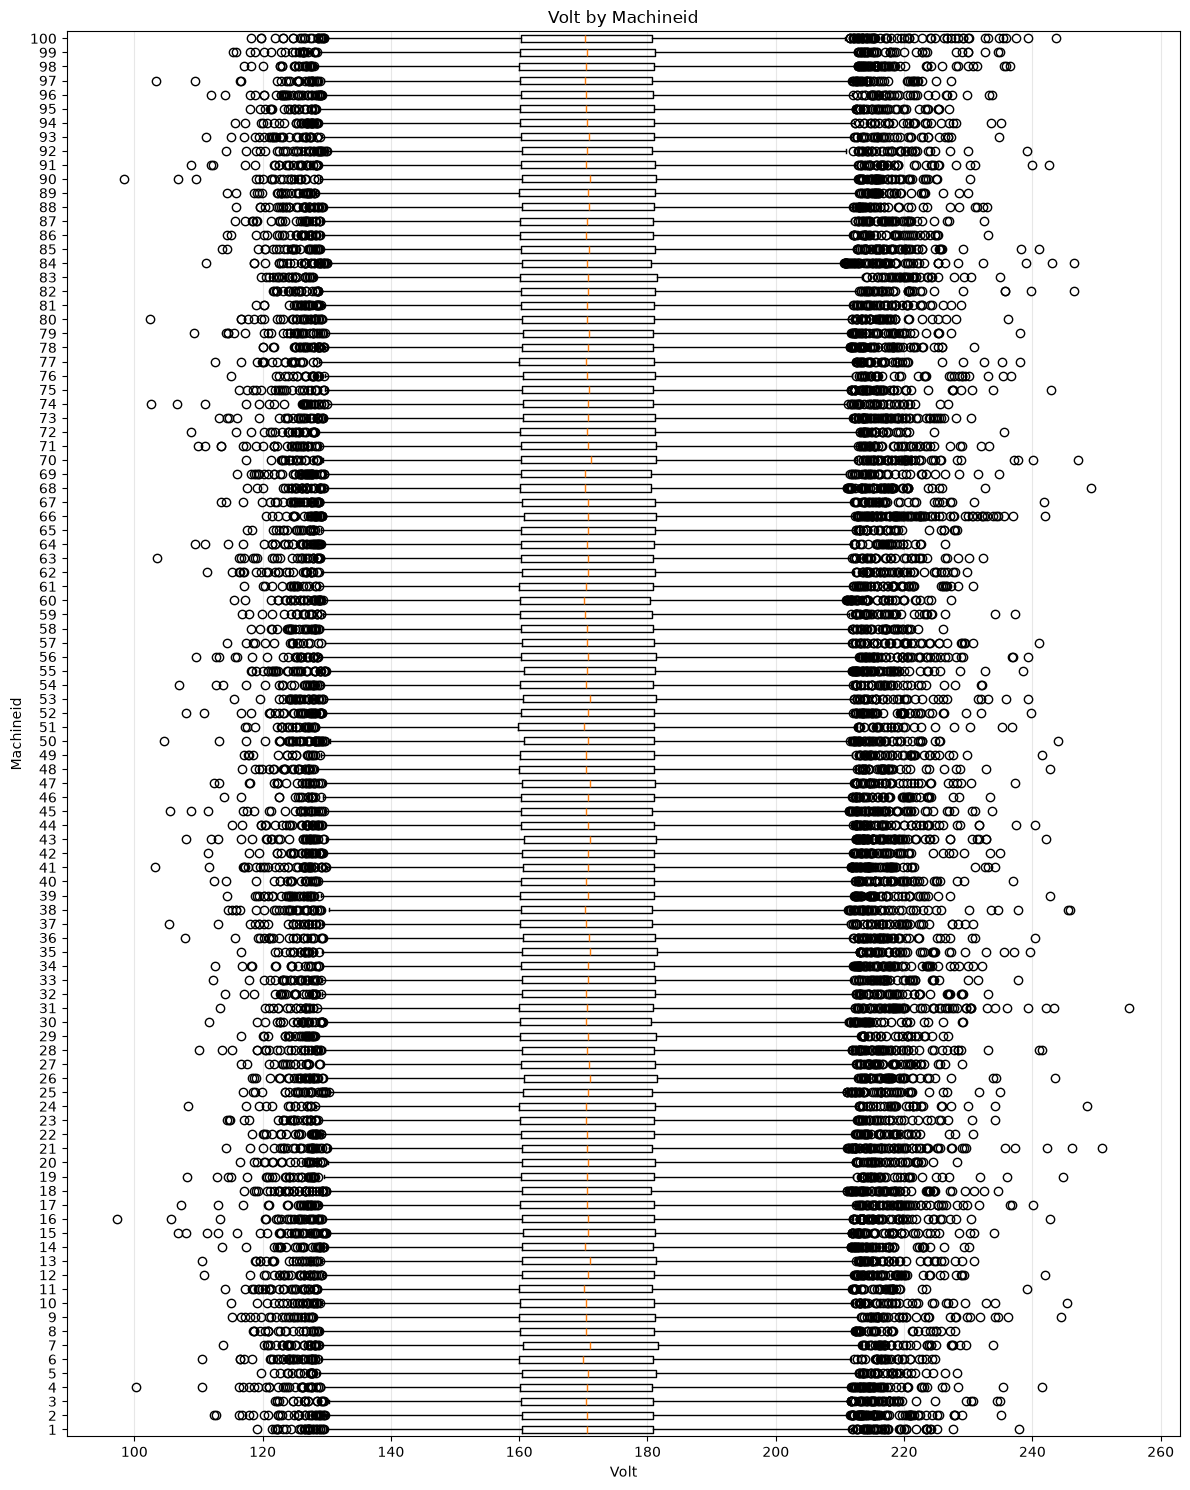

In [18]:
# telemetry_df["month_year"] = telemetry_df["datetime"].dt.to_period("M").astype(str)

def plot_boxh_groupby(data, feature_name, by):
    grouped = data.groupby(by)[feature_name]
    labels = list(grouped.groups.keys())
    values = [grouped.get_group(label).dropna() for label in labels]

    plt.figure(figsize=(12, 15))
    plt.boxplot(values, vert=False, tick_labels=labels)
    plt.title(f"{feature_name.title()} by {by.replace('_', ' ').title()}")
    plt.xlabel(feature_name.title())
    plt.ylabel(by.replace("_", " ").title())
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_boxh_groupby(telemetry_df, feature_name="volt", by="machineID")

### --------------------------------- ERRORS


In [9]:
print(errors_df.info())

<class 'pandas.DataFrame'>
RangeIndex: 3919 entries, 0 to 3918
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   datetime   3919 non-null   str  
 1   machineID  3919 non-null   int64
 2   errorID    3919 non-null   str  
dtypes: int64(1), str(2)
memory usage: 92.0 KB
None


In [19]:
# Transform Data in DataTime
errors_df["datetime"] = pd.to_datetime(errors_df['datetime'])

In [20]:
display(errors_df.head())

,datetime,machineID,errorID
0,2015-01-03 07:00:00,1,error1
1,2015-01-03 20:00:00,1,error3
2,2015-01-04 06:00:00,1,error5
3,2015-01-10 15:00:00,1,error4
4,2015-01-22 10:00:00,1,error4


In [24]:
print("Quantity of errors",failures_df['machineID'].value_counts().unique())
print("\nTop 5 errors By Machine", failures_df['machineID'].value_counts().head(5))
print("\nLeast 5 errors By Machine", failures_df['machineID'].value_counts().tail(5))

Quantity of errors [19 16 15 14 13 12 11 10  9  8  7  6  5  4  3  2]

Top 5 errors By Machine machineID
99    19
98    16
17    15
22    15
37    14
Name: count, dtype: int64

Least 5 errors By Machine machineID
100    3
29     2
46     2
57     2
72     2
Name: count, dtype: int64


In [33]:
def plot_errors_machine(machine_num):

    ## Machine N: telemetry and errors by component
    telemetry_df["datetime"] = pd.to_datetime(telemetry_df["datetime"])
    errors_df["datetime"] = pd.to_datetime(errors_df["datetime"])

    df_machine_1 = telemetry_df[
        telemetry_df["machineID"] == machine_num
    ][["datetime", "volt", "rotate", "pressure", "vibration"]].sort_values("datetime")
    errors_machine = errors_df[
        errors_df["machineID"] == machine_num
    ].sort_values("datetime")

    fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True)

    components = sorted(errors_machine["errorID"].unique())
    component_colors = {
        component: plt.cm.tab10.colors[index % len(plt.cm.tab10.colors)]
        for index, component in enumerate(components)
    }
    variables = {
        "volt": "Voltage",
        "rotate": "Rotation",
        "pressure": "Pressure",
        "vibration": "Vibration",
    }

    for ax, (variable, label) in zip(axes, variables.items()):
        ax.plot(
            df_machine_1["datetime"],
            df_machine_1[variable],
            color="dimgrey",
            linewidth=1,
            alpha=0.8,
            label=label
            
        )
        labeled_components = set()
        for errorID in errors_machine.itertuples(index=False):
            component = errorID.errorID
            ax.axvline(
                errorID.datetime,
                color=component_colors[component],
                linestyle="--",
                linewidth=1.5,
                alpha=0.9,
                label=component if component not in labeled_components else "_nolegend_",
            )
            labeled_components.add(component)
        ax.set_title(f"{label} of Machine {machine_num}" )
        ax.set_ylabel(label)
        ax.grid(True)
        ax.legend(title="Component")

    axes[-1].set_xlabel("Time")
    fig.suptitle(f"Machine {machine_num } Telemetry with Errors", y=1.0)
    fig.tight_layout()
    plt.show()

In [34]:
# vertical_lines = [
#     line
#     for line in axes[0].lines
#     if line.get_linestyle() == "--"
# ]

# print("Líneas verticales en el primer subplot:", len(vertical_lines))

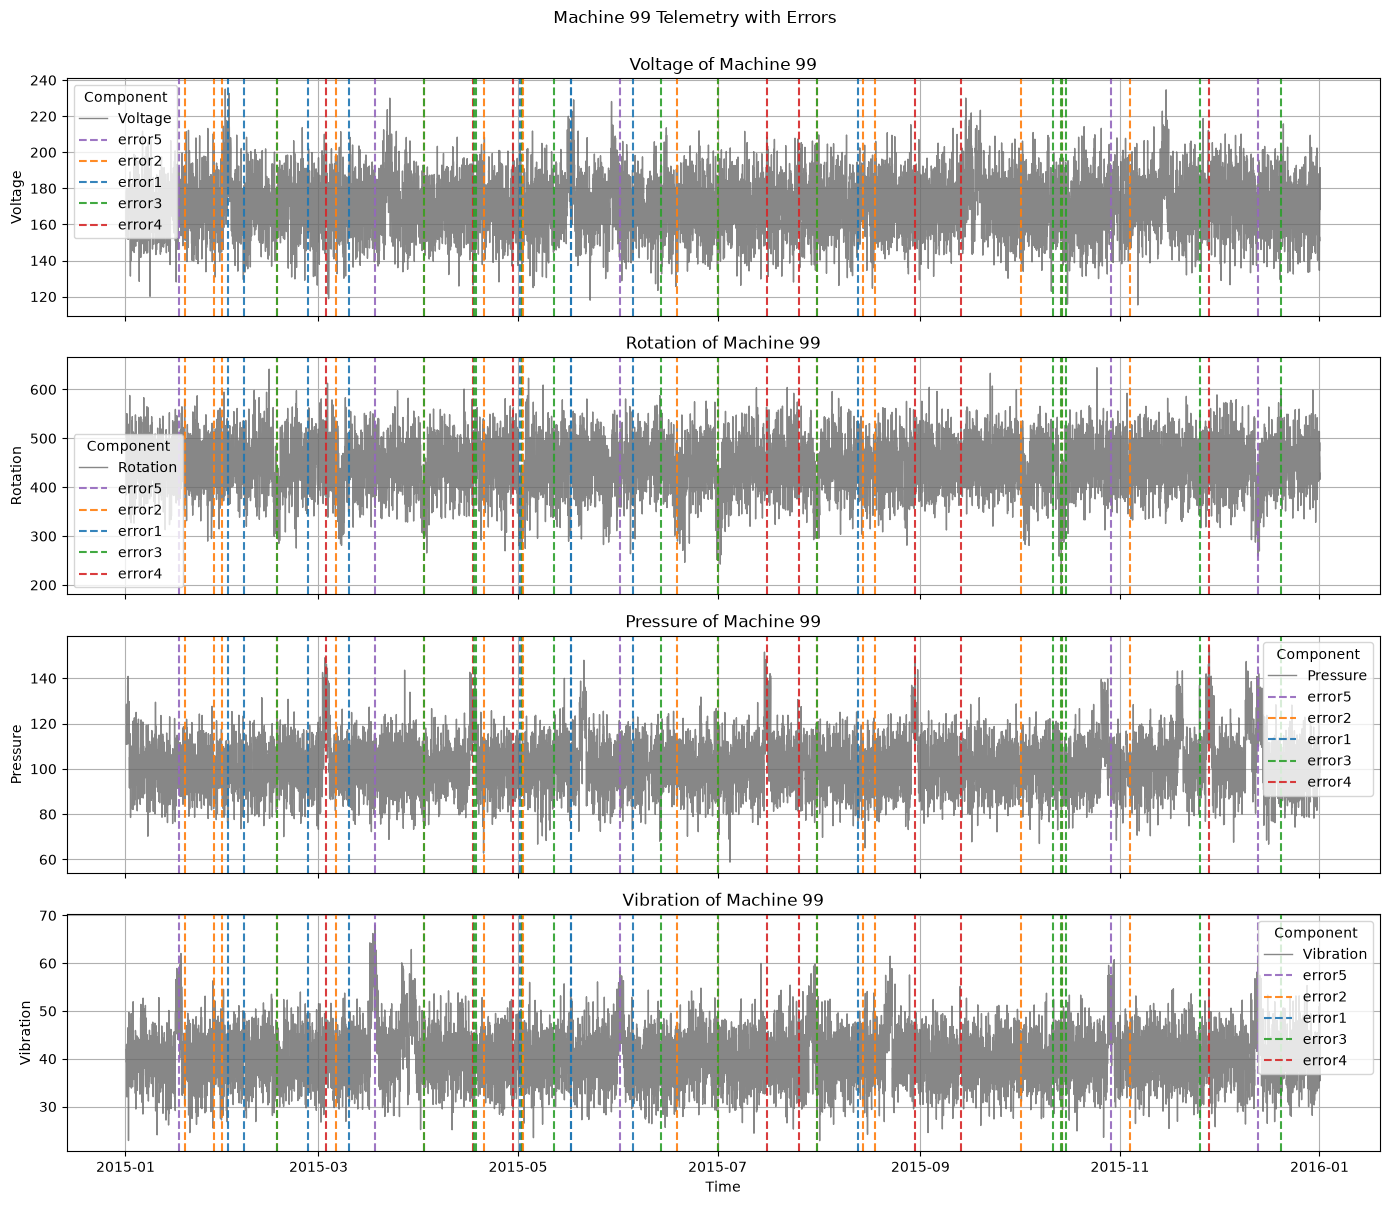

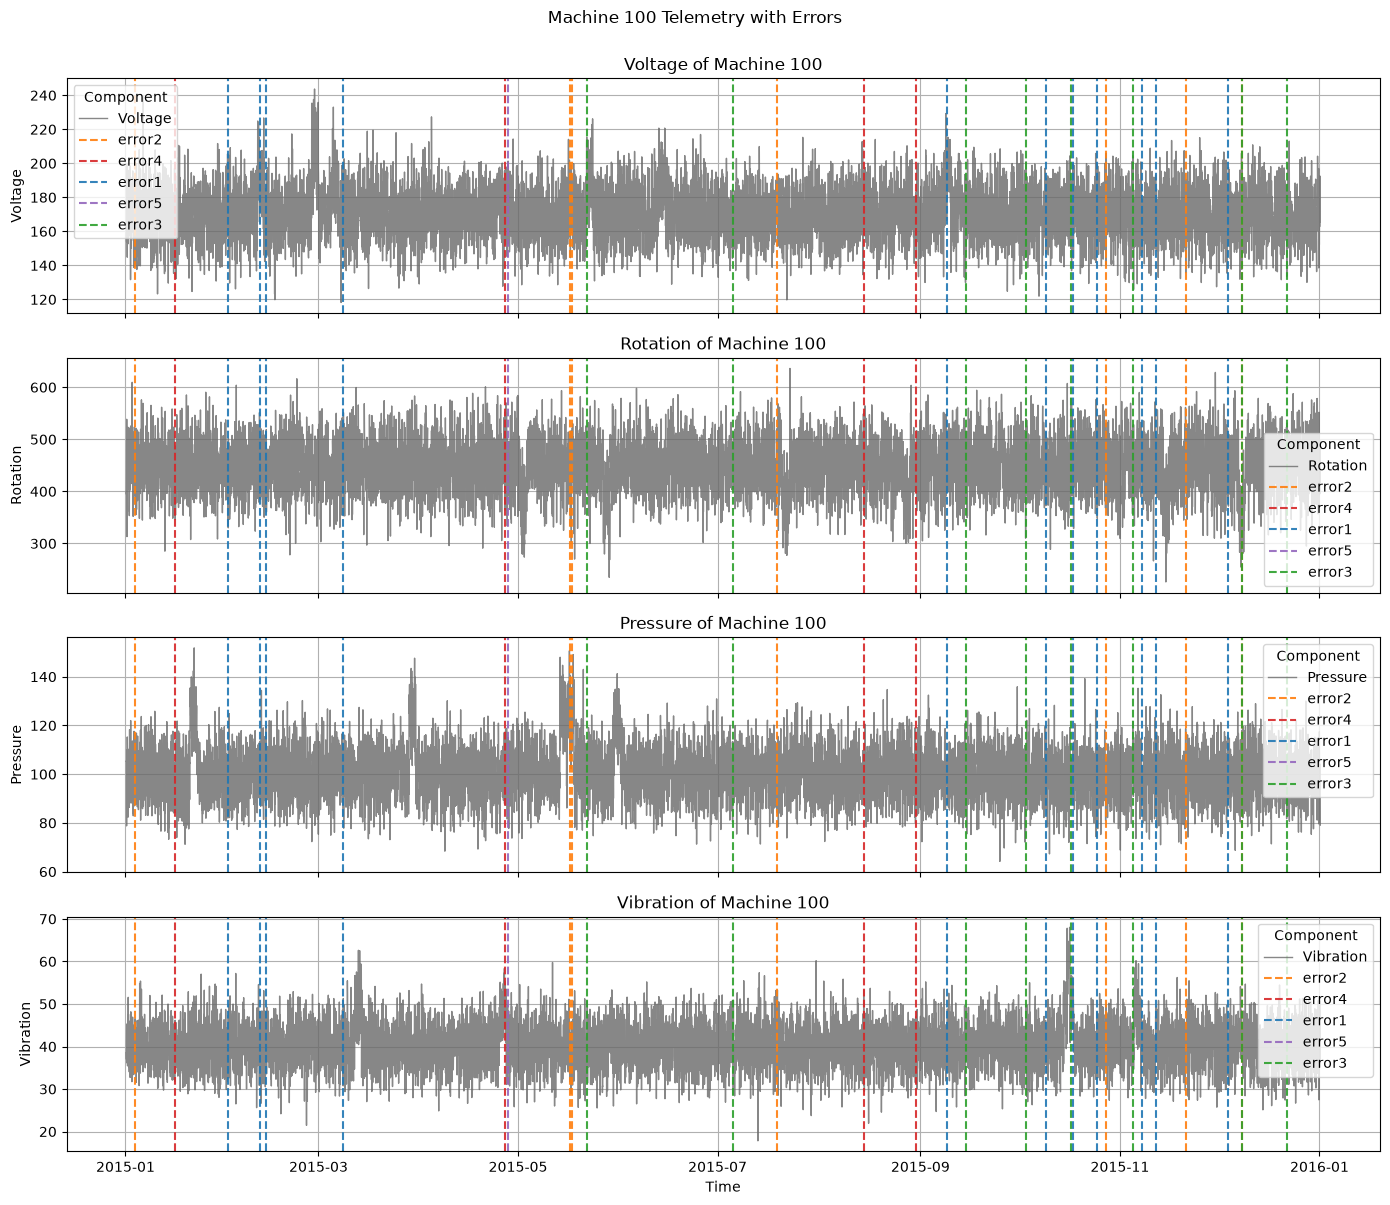

In [27]:
plot_errors_machine(99)
plot_errors_machine(100)

### ------------------------------- 4. MAINT

In [ ]:
print(errors_df.info())

<class 'pandas.DataFrame'>
RangeIndex: 3919 entries, 0 to 3918
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   datetime   3919 non-null   datetime64[us]
 1   machineID  3919 non-null   int64         
 2   errorID    3919 non-null   str           
dtypes: datetime64[us](1), int64(1), str(1)
memory usage: 92.0 KB
None


In [28]:
# Data feature
maint_df["datetime"] = pd.to_datetime(maint_df['datetime'])

### -------------------------- 5. MACHINES

In [ ]:
telemetry_df[telemetry_df.machineID == 1].describe().transpose()

,count,mean,min,25%,50%,75%,max,std
datetime,8761,2015-07-02 18:00:00,2015-01-01 06:00:00,2015-04-02 12:00:00,2015-07-02 18:00:00,2015-10-02 00:00:00,2016-01-01 06:00:00,NaN
machineID,8761.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0
volt,8761.0,170.833898,119.059047,160.382124,170.618459,180.929341,237.938518,15.314388
rotate,8761.0,446.336502,215.619476,412.348209,447.704679,481.358342,636.364569,52.224261
pressure,8761.0,100.668306,58.733724,93.320867,100.319242,107.377475,155.257527,10.860264
vibration,8761.0,40.586309,22.666865,36.847203,40.417442,44.004311,67.633435,5.542143


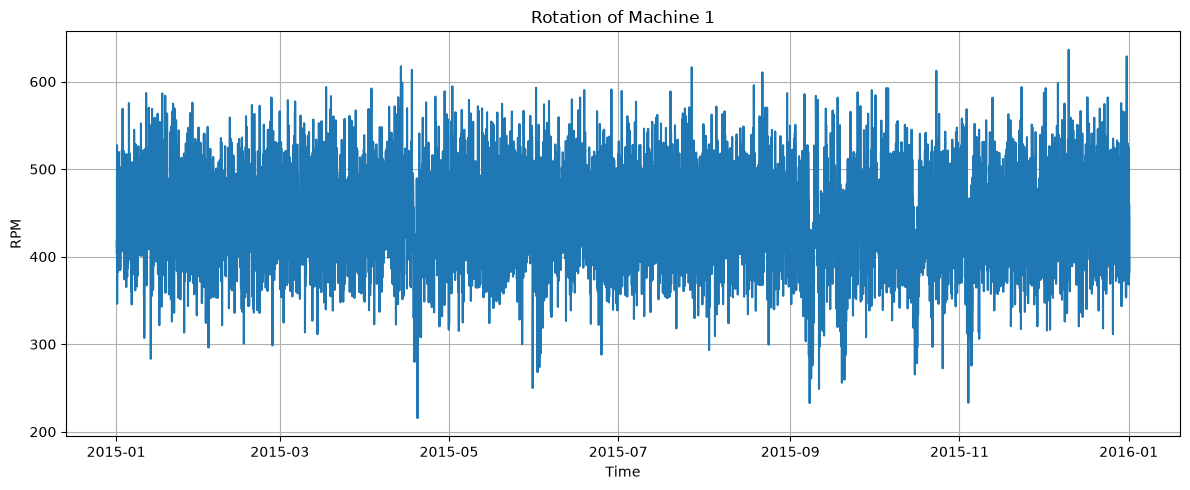

In [ ]:
# Machine 1: vibration, period 2015
telemetry_df["datetime"] = pd.to_datetime(telemetry_df["datetime"])
df_vib_machine_1 = telemetry_df[
    telemetry_df["machineID"] == 1
][["datetime", "rotate"]].set_index("datetime")

plt.figure(figsize=(12, 5))
plt.plot(df_vib_machine_1.index, df_vib_machine_1["rotate"])
plt.title("Rotation of Machine 1")
plt.xlabel("Time")
plt.ylabel("RPM")
plt.grid(True)
plt.tight_layout()
plt.show()

## Machine Number: telemetry and failures by component


### FAILURES

In [ ]:
print(failures_df.info())

<class 'pandas.DataFrame'>
RangeIndex: 761 entries, 0 to 760
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   datetime   761 non-null    datetime64[us]
 1   machineID  761 non-null    int64         
 2   failure    761 non-null    str           
dtypes: datetime64[us](1), int64(1), str(1)
memory usage: 18.0 KB
None


In [ ]:
print(failures_df['machineID'].value_counts().tail(20))

machineID
96     5
2      4
14     4
36     4
39     4
44     4
50     4
60     4
61     4
68     4
82     4
86     4
27     3
34     3
41     3
100    3
29     2
46     2
57     2
72     2
Name: count, dtype: int64


--------------------------------
## Behavior of machines per failures gruped by <15 or ID 

In [ ]:
few_fails = (
    failures_df["machineID"]
    .value_counts()
    .rename_axis("machineID")
    .reset_index(name="failure_count")
)

few_fails["Few Fails"] = few_fails["failure_count"] < 15

display(few_fails)


,machineID,failure_count,Few Fails
0,99,19,False
1,98,16,False
2,17,15,False
3,22,15,False
4,37,14,True
...,...,...,...
93,100,3,True
94,29,2,True
95,46,2,True
96,57,2,True


-------------------------------

In [31]:
def plot_fail_machine(machine_num):

    ## Machine N: telemetry and failures by component
    telemetry_df["datetime"] = pd.to_datetime(telemetry_df["datetime"])
    failures_df["datetime"] = pd.to_datetime(failures_df["datetime"])

    df_machine_1 = telemetry_df[
        telemetry_df["machineID"] == machine_num
    ][["datetime", "volt", "rotate", "pressure", "vibration"]].sort_values("datetime")
    failures_machine = failures_df[
        failures_df["machineID"] == machine_num
    ].sort_values("datetime")

    fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True)

    components = sorted(failures_machine["failure"].unique())
    component_colors = {
        component: plt.cm.tab10.colors[index % len(plt.cm.tab10.colors)]
        for index, component in enumerate(components)
    }
    variables = {
        "volt": "Voltage",
        "rotate": "Rotation",
        "pressure": "Pressure",
        "vibration": "Vibration",
    }

    for ax, (variable, label) in zip(axes, variables.items()):
        ax.plot(
            df_machine_1["datetime"],
            df_machine_1[variable],
            color="dimgrey",
            linewidth=1,
            alpha=0.8,
            label=label
            
        )
        labeled_components = set()
        for failure in failures_machine.itertuples(index=False):
            component = failure.failure
            ax.axvline(
                failure.datetime,
                color=component_colors[component],
                linestyle="--",
                linewidth=1.5,
                alpha=0.9,
                label=component if component not in labeled_components else "_nolegend_",
            )
            labeled_components.add(component)
        ax.set_title(f"{label} of Machine {machine_num}" )
        ax.set_ylabel(label)
        ax.grid(True)
        ax.legend(title="Component")

    axes[-1].set_xlabel("Time")
    fig.suptitle(f"Machine {machine_num } Telemetry with Failures", y=1.0)
    fig.tight_layout()
    plt.show()

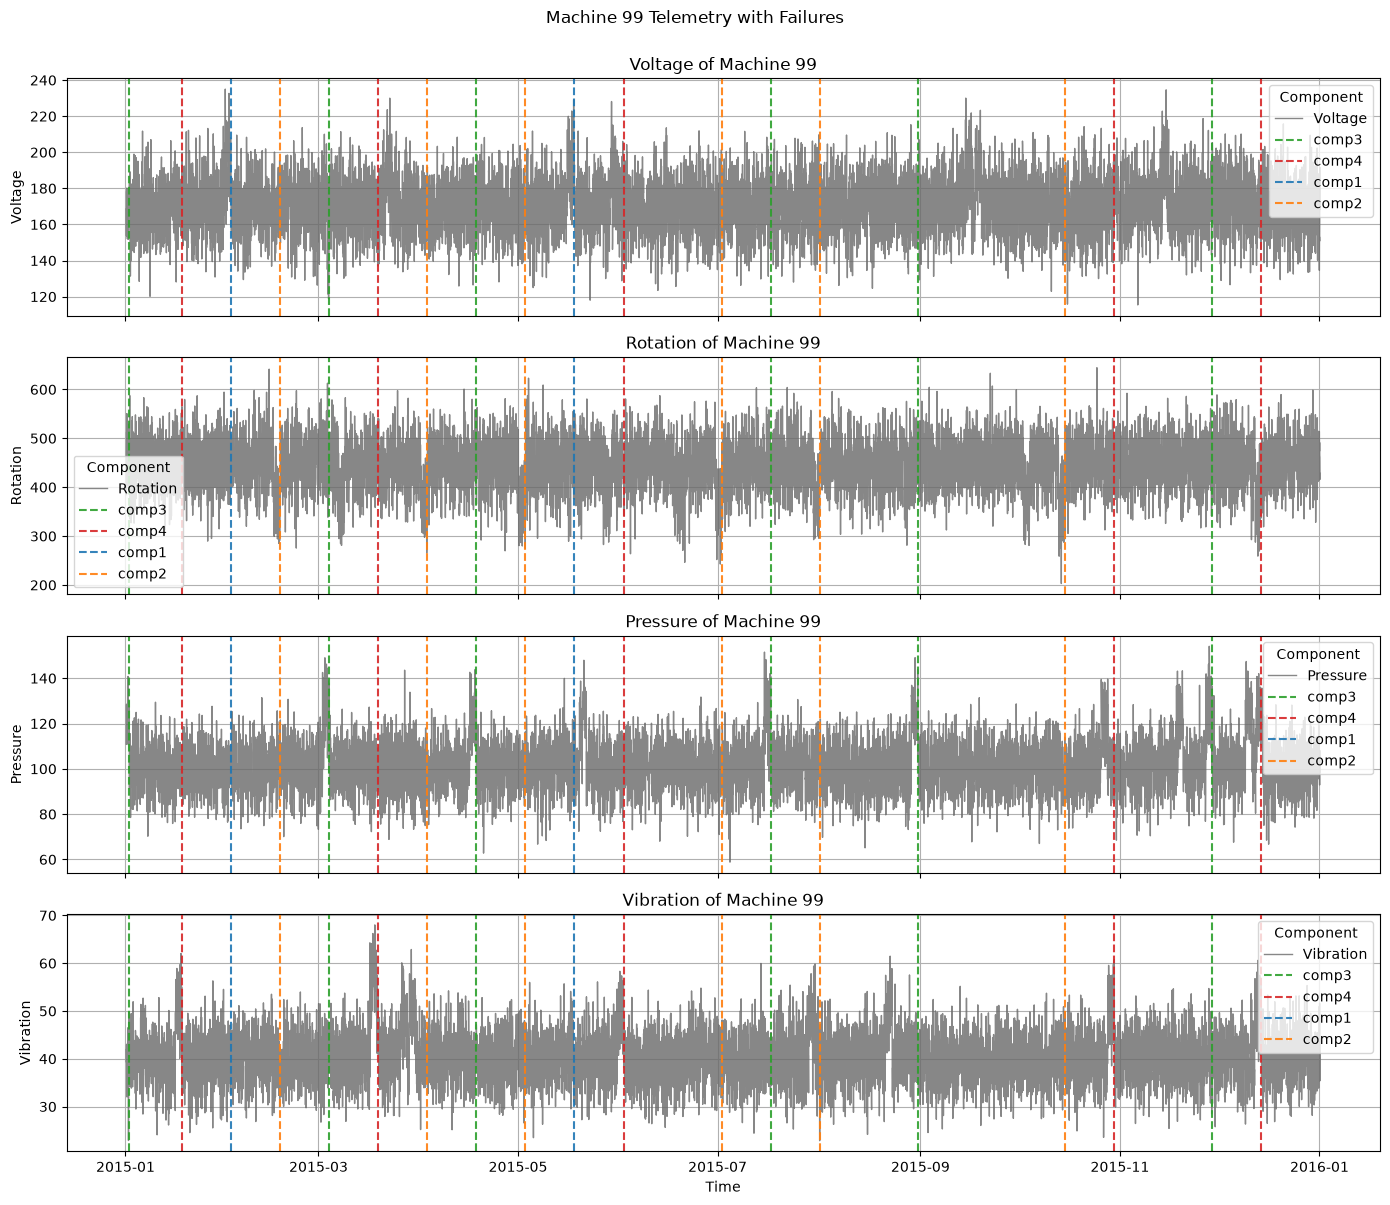

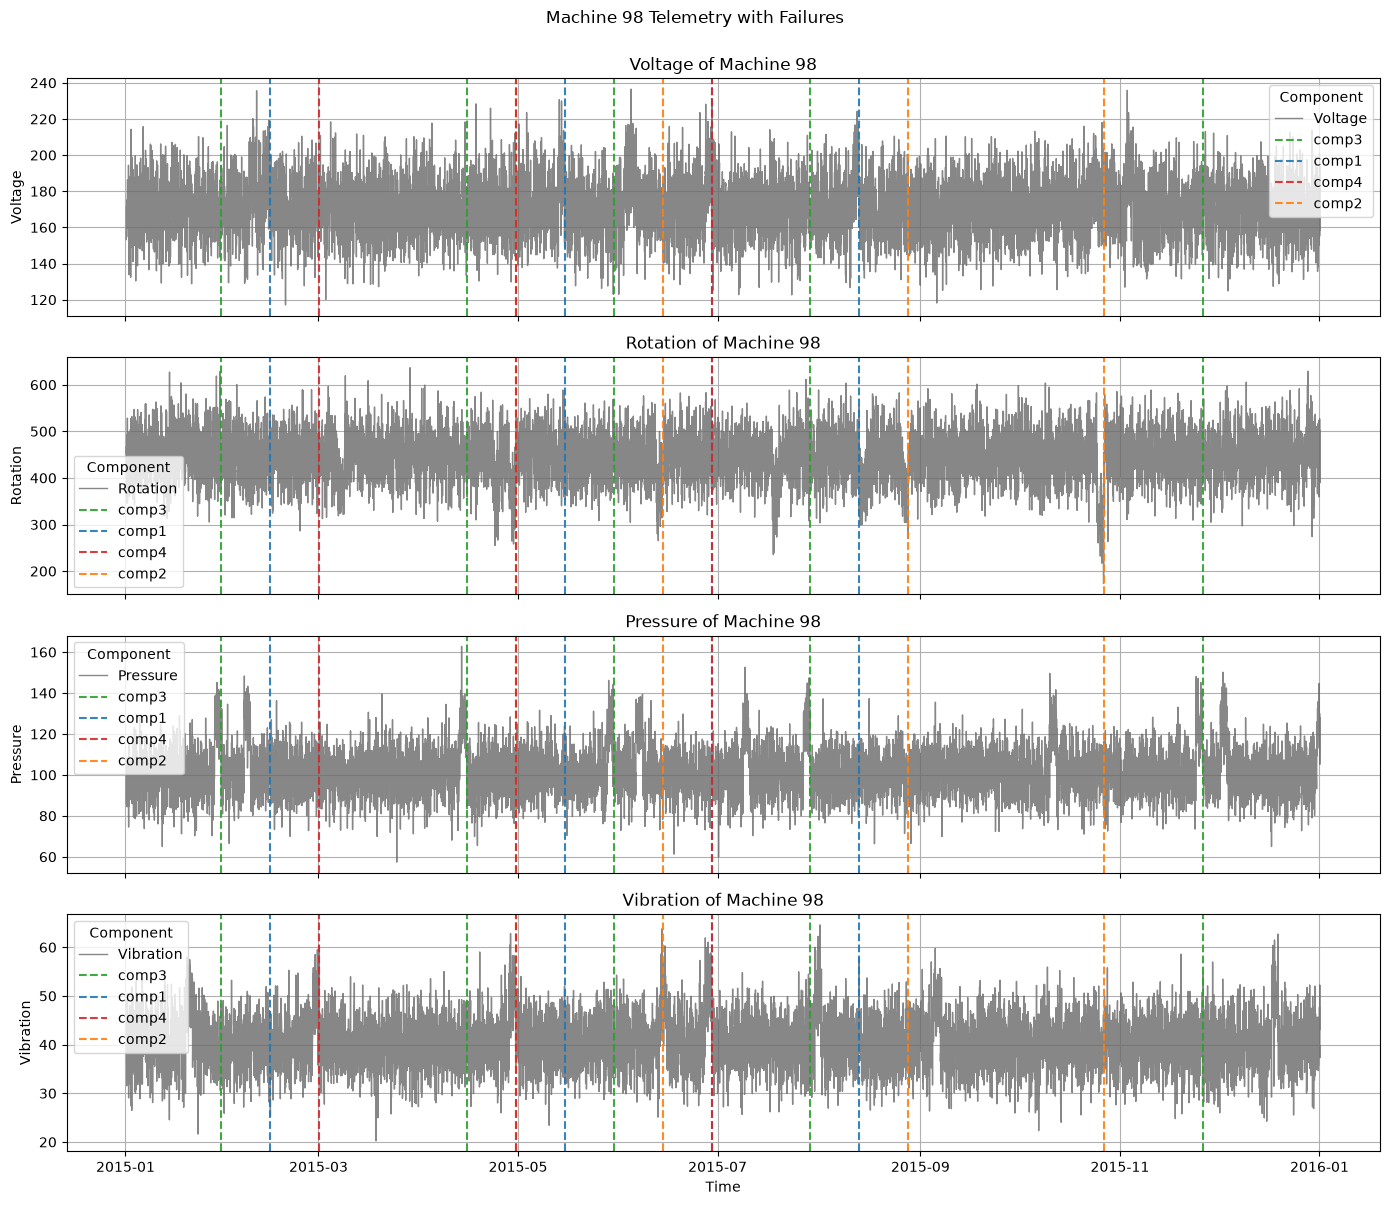

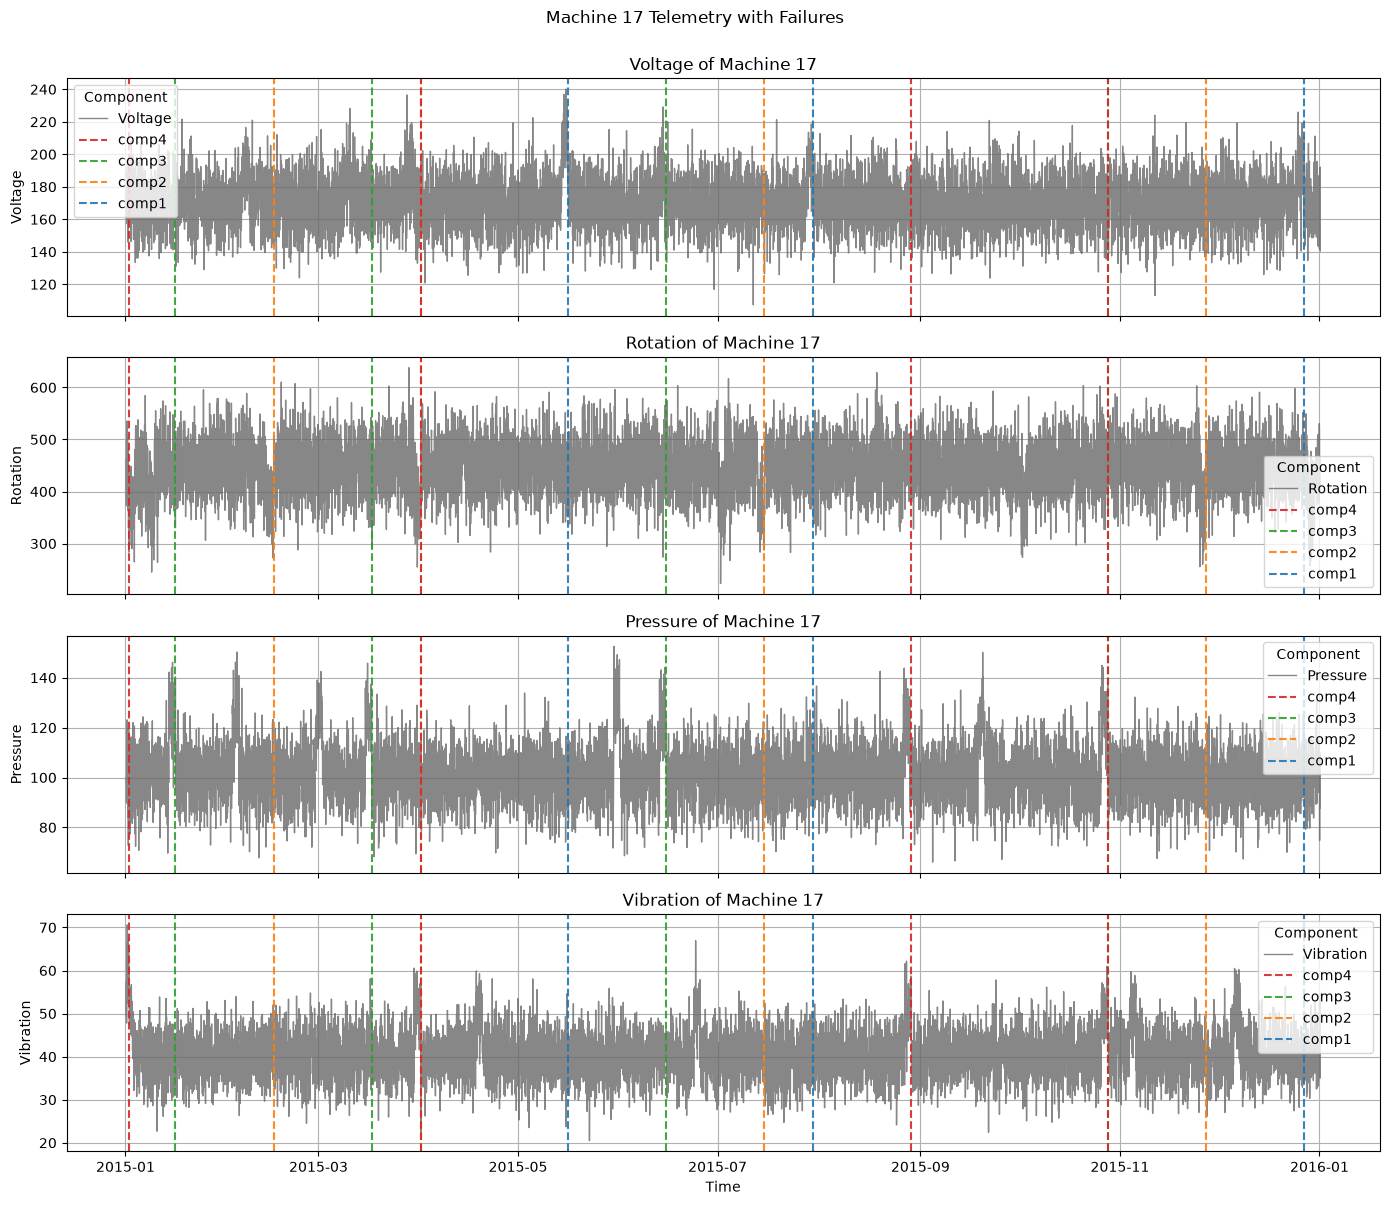

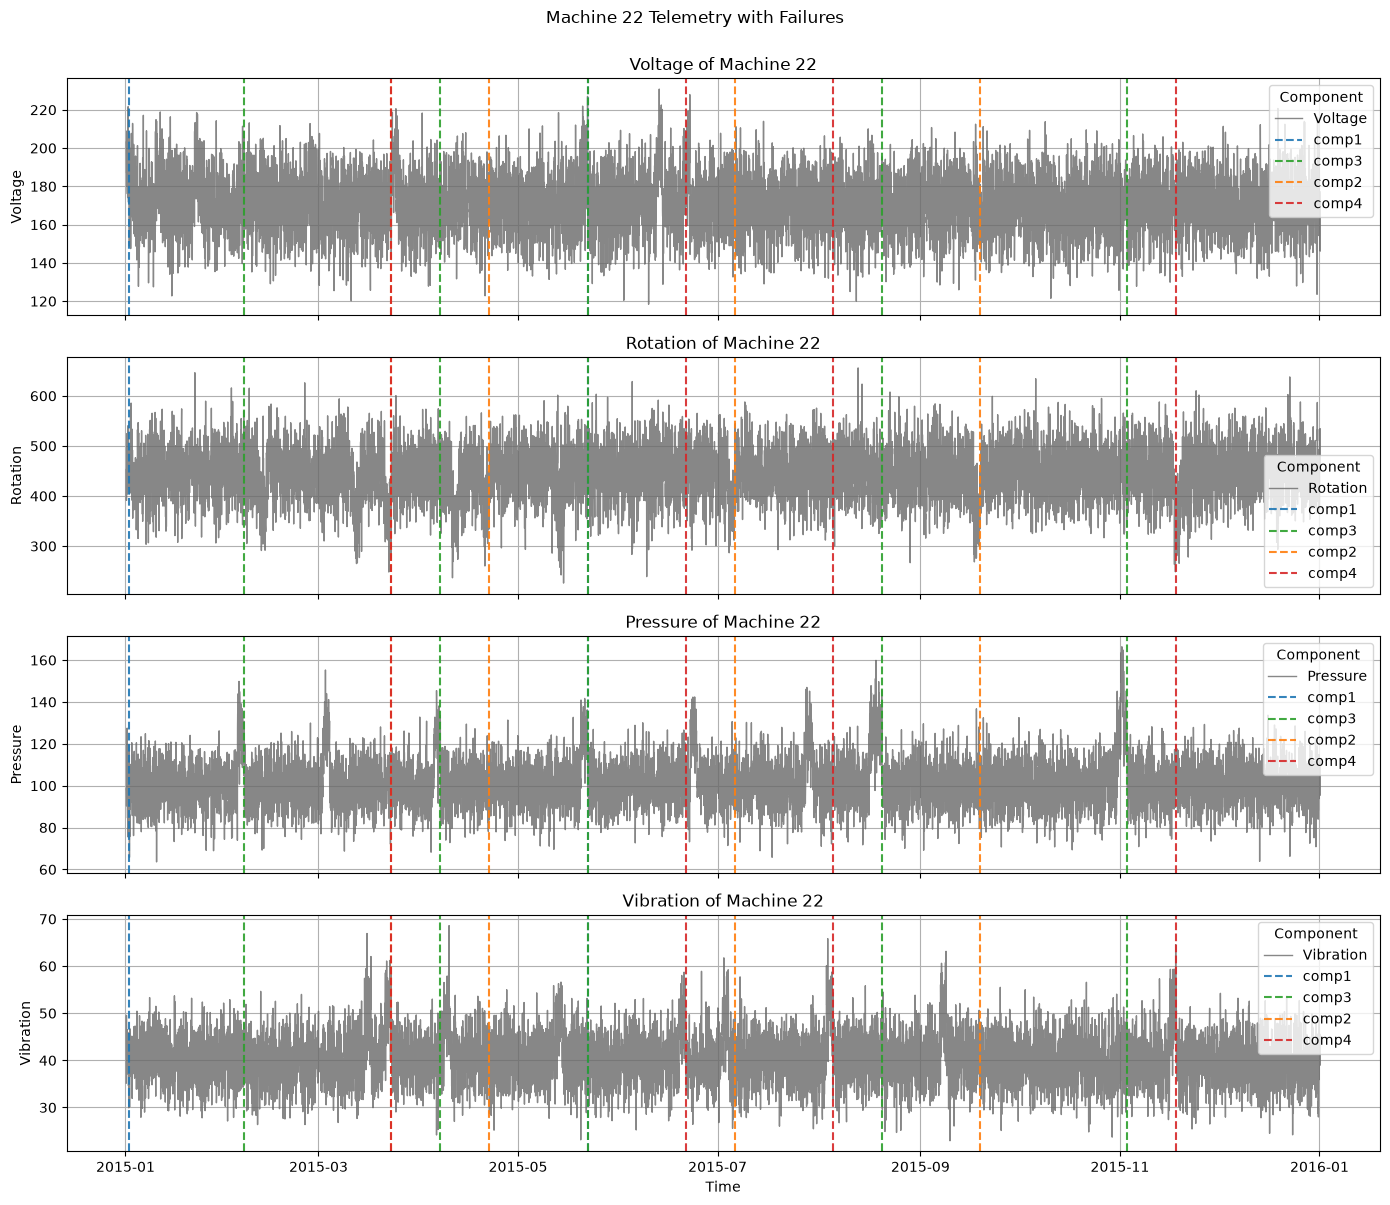

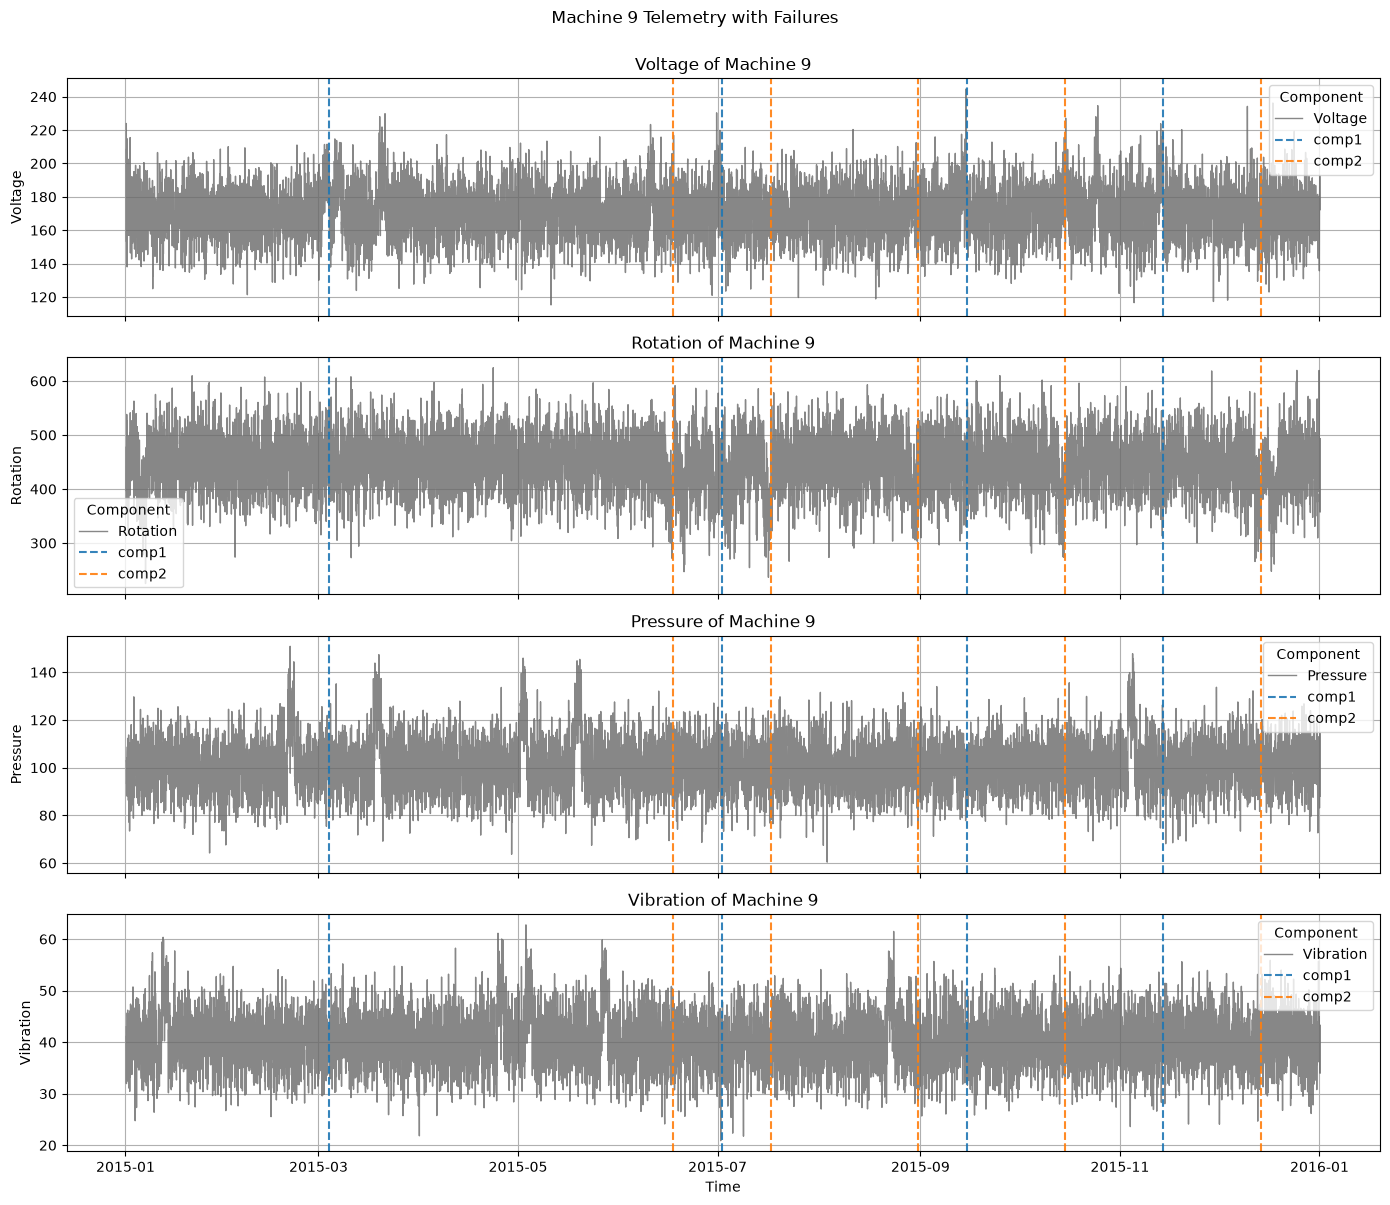

In [35]:
# Machines taked from: Behavior of machines per failures gruped by <15 or ID table
plot_fail_machine(99)
plot_fail_machine(98)
plot_fail_machine(17)
plot_fail_machine(22)
plot_fail_machine(9)

Component 1 (Blue): Failure events appear to be consistently preceded by voltage spikes, suggesting a temporal correlation between abnormal increases in voltage and subsequent component degradation or failure. Voltage excursions may therefore serve as an early warning indicator for this component.

Component 2 (Orange): Failures tend to occur after significant drops in rotational speed, indicating that decreases in rotation may reflect deteriorating operating conditions or mechanical inefficiencies leading to component failure.

Component 3 (Green): A recurring pattern shows that failures are often preceded by sudden pressure decreases. This behavior suggests that pressure loss may be a key predictive signal associated with the failure mechanism of this component.

Component 4 (Red): Failure events are commonly observed following elevated vibration peaks, indicating a potential relationship between excessive vibration levels and the onset of mechanical degradation, imbalance, or structural wear.

These observations suggest that voltage, rotation, pressure, and vibration may serve as valuable predictive features for condition monitoring and predictive maintenance models, enabling the early detection of anomalous operating states prior to component failure.